In [1]:
import pandas as pd
from datasets import load_dataset

# Chargement du dataset officiel Allociné (avec le bon namespace !)
print("Téléchargement du dataset Allociné...")
dataset = load_dataset("tblard/allocine")

# Conversion en DataFrames Pandas
df_train = pd.DataFrame(dataset['train'])
df_val = pd.DataFrame(dataset['validation'])
df_test = pd.DataFrame(dataset['test'])

print(f"Taille du jeu d'entraînement : {len(df_train)}")
df_train.head()

Téléchargement du dataset Allociné...


Taille du jeu d'entraînement : 160000


,review,label
0,Si vous cherchez du cinéma abrutissant à tous ...,0
1,"Trash, re-trash et re-re-trash...! Une horreur...",0
2,"Et si, dans les 5 premières minutes du film, l...",0
3,Mon dieu ! Quelle métaphore filée ! Je suis ab...,0
4,"Premier film de la saga Kozure Okami, ""Le Sabr...",1


In [2]:
import spacy
from tqdm import tqdm

#activer tqdm pour pandas
tqdm.pandas()

#chargement du modele linguistique francais de spaCy
nlp = spacy.load("fr_core_news_sm")

def clean_text_fr(text):
    #traitement du text via spaCy
    doc = nlp(text)
    # on garde les mots qui ne sont pas de la ponctuation, pas des stop words, 
    #qui contiennent des lettres, et on rpend  leur forme de base  (lemme) en miniscule
    tokens = [
        token.lemma_.lower() for token in doc
        if not token.is_punct and not token.is_stop and token.is_alpha
    ]
    return " ".join(tokens)
#test sur la premiere critique  
review_test= df_train['review'].iloc[0]
print("avant :", review_test)
print("\nApres: ", clean_text_fr(review_test))

avant : Si vous cherchez du cinéma abrutissant à tous les étages,n'ayant aucune peur du cliché en castagnettes et moralement douteux,"From Paris with love" est fait pour vous.Toutes les productions Besson,via sa filière EuropaCorp ont de quoi faire naître la moquerie.Paris y est encore une fois montrée comme une capitale exotique,mais attention si l'on se dirige vers la banlieue,on y trouve tout plein d'intégristes musulmans prêts à faire sauter le caisson d'une ambassadrice américaine.Nauséeux.Alors on se dit qu'on va au moins pouvoir apprécier la déconnade d'un classique buddy-movie avec le jeune agent aux dents longues obligé de faire équipe avec un vieux lou complètement timbré.Mais d'un côté,on a un Jonathan Rhys-meyers fayot au possible,et de l'autre un John Travolta en total délire narcissico-badass,crâne rasé et bouc proéminent à l'appui.Sinon,il n'y a aucun scénario.Seulement,des poursuites débiles sur l'autoroute,Travolta qui étale 10 mecs à l'arme blanche en 8 mouvements(!!)

In [3]:
#echantillonnage ppour iterer  rapidement  
df_train_sample= df_train.sample(5000, random_state=42).copy()
df_test_sample =df_test.sample(1000, random_state=42).copy()

print("Nettoyage dujeu d'entrainement (envrion 1-2 minutes)...")
df_train_sample['review_clean'] = df_train_sample['review'].progress_apply(clean_text_fr)
print("Nettoyage du jeu de test....")
df_test_sample['review_clean']= df_test_sample['review'].progress_apply(clean_text_fr)
df_train_sample[['review', 'review_clean','label']].head(3)

Nettoyage dujeu d'entrainement (envrion 1-2 minutes)...


100%|██████████| 5000/5000 [02:34<00:00, 32.27it/s]


Nettoyage du jeu de test....


100%|██████████| 1000/1000 [00:25<00:00, 39.94it/s]


,review,review_clean,label
120476,Un excellent thriller d'action où les scènes d...,excellent thriller action scène bravoure crois...,1
32693,"Si le scénariste, qui aurait pu faire un minim...",scénariste faire minimum recherche éviter film...,0
79958,"Référence dans la filmographie de Bogart, ""Le ...",référence filmographie bogart violent décevant...,0


entrainement du modele baseline
Évaluation sur le jeu de test...
              precision    recall  f1-score   support

           0       0.88      0.90      0.89       510
           1       0.90      0.87      0.88       490

    accuracy                           0.89      1000
   macro avg       0.89      0.89      0.89      1000
weighted avg       0.89      0.89      0.89      1000



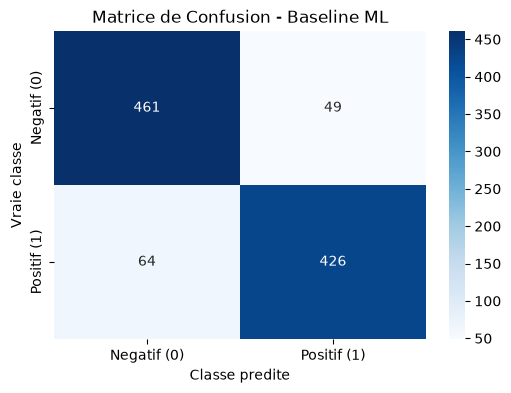

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
#creation du  pipeline ML
pipeline= Pipeline([
        ('tfidf',TfidfVectorizer(max_features=5000, ngram_range=(1,2))),
        ('clf',LogisticRegression(random_state=42, max_iter=1000))
    ])
print("entrainement du modele baseline")
pipeline.fit(df_train_sample['review_clean'],df_train_sample['label'])

print("Évaluation sur le jeu de test...")
y_pred= pipeline.predict(df_test_sample['review_clean'])

# Affichage des métriques de classification
print(classification_report(df_test_sample['label'],y_pred))

# Génération de la matrice de confusion
plt.figure(figsize=(6,4))
cm= confusion_matrix(df_test_sample['label'],y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Negatif (0)', 'Positif (1)'],
            yticklabels=['Negatif (0)', 'Positif (1)'])
plt.title('Matrice de Confusion - Baseline ML')
plt.ylabel('Vraie classe')
plt.xlabel('Classe predite')
plt.show()

In [5]:
import mlflow
import mlflow.sklearn
from sklearn.metrics import accuracy_score, f1_score

# Définir le nom du projet/expérience dans MLflow
mlflow.set_experiment("Allocine_Sentiment_Analysis")

# Activer le tracking automatique pour Scikit-Learn
mlflow.sklearn.autolog()

# Démarrer une nouvelle "run" (expérience)
with mlflow.start_run(run_name="Baseline_TFIDF_LogReg"):
    print("Entraînement avec tracking MLflow...")
    # On réutilise le pipeline défini à l'étape précédente
    pipeline.fit(df_train_sample['review_clean'], df_train_sample['label'])
    
    print("Prédictions...")
    y_pred = pipeline.predict(df_test_sample['review_clean'])
    
    # Affichage rapide dans le notebook
    acc = accuracy_score(df_test_sample['label'], y_pred)
    print(f"Précision (Accuracy) : {acc:.4f}")
    print("Va voir sur http://127.0.0.1:5000, ton modèle, ses paramètres et sa matrice de confusion y sont sauvegardés !")

2026/10/09 23:33:14 WARNING mlflow.sklearn: Unrecognized dataset type <class 'pandas.core.series.Series'>. Dataset logging skipped.


Entraînement avec tracking MLflow...


2026/10/09 23:33:16 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/10/09 23:33:27 WARNING mlflow.sklearn: Unrecognized dataset type <class 'pandas.core.series.Series'>. Dataset logging skipped.
C:\Users\TRETEC\Documents\nlp-sentiment-france\venv\Lib\site-packages\sklearn\metrics\_classification.py:3424: FutureWarning: `y_pred` was renamed to `y_proba` in version 1.9 and will be removed in 1.11. Use `y_proba` instead.
  warnings.warn(
2026/10/09 23:33:30 WARNING mlflow.sklearn: Unrecognized dataset type <class 'pandas.core.series.Series'>. Dataset logging skipped.


Prédictions...
Précision (Accuracy) : 0.8870
Va voir sur http://127.0.0.1:5000, ton modèle, ses paramètres et sa matrice de confusion y sont sauvegardés !


In [7]:
import torch
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

print("Préparation des données pour CamemBERT...")
# On prend un mini-échantillon pour ne pas faire exploser ton PC
df_train_tiny = df_train_sample.sample(200, random_state=42)
df_test_tiny = df_test_sample.sample(50, random_state=42)

# Conversion Pandas -> Hugging Face Dataset
hg_train = Dataset.from_pandas(df_train_tiny)
hg_test = Dataset.from_pandas(df_test_tiny)

# 1. Chargement du Tokenizer (il découpe le texte comme CamemBERT aime)
tokenizer = AutoTokenizer.from_pretrained("camembert-base")

def tokenize_function(examples):
    # On limite à 128 mots pour accélérer le calcul
    return tokenizer(examples["review"], padding="max_length", truncation=True, max_length=128)

print("Tokenization en cours...")
tokenized_train = hg_train.map(tokenize_function, batched=True)
tokenized_test = hg_test.map(tokenize_function, batched=True)

# 2. Chargement du Modèle Vierge
print("Téléchargement du modèle CamemBERT...")
model = AutoModelForSequenceClassification.from_pretrained("camembert-base", num_labels=2)

# 3. Fonction pour calculer les métriques
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, predictions),
        "f1": f1_score(labels, predictions)
    }

# 4. Configuration de l'entraînement (Correction : eval_strategy)
    training_args = TrainingArguments(
        output_dir="./camembert_results",
        num_train_epochs=3,                   # 3 passages sur les données
        per_device_train_batch_size=8,        # Traitement par paquets de 8
        eval_strategy="epoch",                # Évaluation à chaque fin d'époque (CORRIGÉ)
        logging_dir='./logs',
    )

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=tokenized_train,
        eval_dataset=tokenized_test,
        compute_metrics=compute_metrics,
    )

    print("Démarrage de l'entraînement (ça va prendre quelques minutes)...")
    trainer.train()

Préparation des données pour CamemBERT...
Tokenization en cours...


Map:   0%|          | 0/200 [00:00<?, ? examples/s]

Map:   0%|          | 0/50 [00:00<?, ? examples/s]

Téléchargement du modèle CamemBERT...


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] CamembertForSequenceClassification LOAD REPORT from: camembert-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
